Iter  x              f(x)           f'(x)          
---------------------------------------------------
1     1.000000       16.000000      10.000000      
2     0.200000       10.240000      8.000000       
3     -0.440000      6.553600       6.400000       
4     -0.952000      4.194304       5.120000       
5     -1.361600      2.684355       4.096000       
6     -1.689280      1.717987       3.276800       
7     -1.951424      1.099512       2.621440       
8     -2.161139      0.703687       2.097152       
9     -2.328911      0.450360       1.677722       
10    -2.463129      0.288230       1.342177       
11    -2.570503      0.184467       1.073742       
16    -2.859263      0.019807       0.351844       
21    -2.953883      0.002127       0.115292       
26    -2.984888      0.000228       0.037779       
31    -2.995048      0.000025       0.012379       
36    -2.998377      0.000003       0.004056       
41    -2.999468      0.000000       0.001329       
46    -2.999

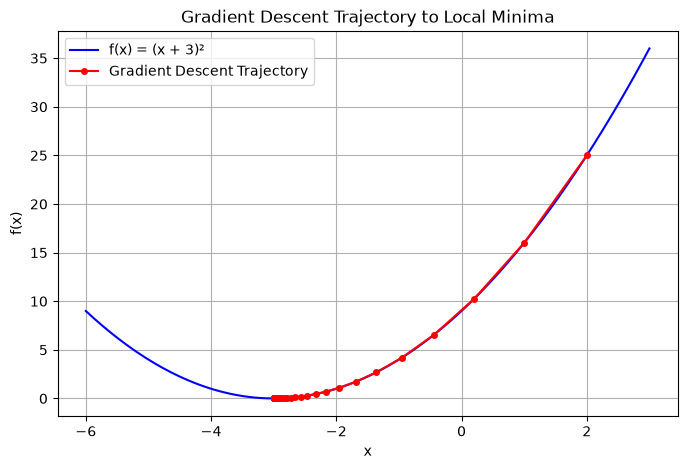

In [1]:
# ==============================================================================
# ASSIGNMENT 4: GRADIENT DESCENT ALGORITHM
# ==============================================================================
# ALGORITHM & OBJECTIVE:
#   Find the local minimum of a convex objective function:
#       Objective Function:  y = f(x) = (x + 3)^2
#       First Derivative:    dy/dx = f'(x) = 2 * (x + 3)
#
#   Parameter Update Rule:
#       x_{t+1} = x_t - eta * f'(x_t)
#       where eta is the learning rate.
#
#   Convergence Criteria:
#       Stop when |x_{t+1} - x_t| < precision OR iteration >= max_iters.
#
# THEORETICAL MINIMUM:
#   f'(x) = 0 => 2 * (x + 3) = 0 => x = -3, y = 0
#
# TIME & SPACE COMPLEXITIES:
#   - Time Complexity: O(T), where T is the number of iterations until convergence (T <= max_iters).
#   - Space Complexity: O(1) auxiliary space (scalar variable updates).
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np

# Define target objective and analytical derivative
def objective(x):
    return (x + 3)**2

def derivative(x):
    return 2 * (x + 3)

def gradient_descent(initial_x=2.0, learning_rate=0.1, precision=1e-6, max_iters=1000):
    cur_x = initial_x
    history_x = [cur_x]
    history_y = [objective(cur_x)]
    
    print(f"{'Iter':<6}{'x':<15}{'f(x)':<15}{'f\'(x)':<15}")
    print("-" * 51)
    
    for i in range(max_iters):
        grad = derivative(cur_x)
        prev_x = cur_x
        
        # Gradient descent step
        cur_x = cur_x - learning_rate * grad
        
        history_x.append(cur_x)
        history_y.append(objective(cur_x))
        
        if (i < 10) or (i % 5 == 0):
            print(f"{i+1:<6}{cur_x:<15.6f}{objective(cur_x):<15.6f}{grad:<15.6f}")
            
        # Check termination condition
        if abs(cur_x - prev_x) < precision:
            print(f"\nConverged in {i+1} iterations.")
            break
            
    return cur_x, objective(cur_x), history_x, history_y

# Execute optimization
start_point = 2.0
lr = 0.1
min_x, min_y, x_hist, y_hist = gradient_descent(initial_x=start_point, learning_rate=lr)

print("=" * 40)
print(f"Calculated Local Minima at x = {min_x:.6f}")
print(f"Minimum function value f(x) = {min_y:.6f}")
print("=" * 40)

# Visualization of convergence trajectory
x_vals = np.linspace(-6, 3, 200)
y_vals = objective(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label='f(x) = (x + 3)²', color='blue')
plt.plot(x_hist, y_hist, 'ro-', label='Gradient Descent Trajectory', markersize=4)
plt.title('Gradient Descent Trajectory to Local Minima')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()